# Exercises: Neural Networks (NN) and Convolutional Neural Networks (CNN) on MNIST

In this part you will:

1. Implement a **fully connected neural network (FNN)** for the MNIST digit classification task.
2. Implement a **convolutional neural network (CNN)** for the same task.

Please fill in all parts marked with **`TODO`** in the code cells. The code is using PyTorch.

You can try to write your own code in tensorflow if you are interested in other packages.

In [9]:
# @title Imports and basic setup

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import accuracy_score, f1_score  # used in evaluation

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)
if device.type == "cuda":
    torch.cuda.manual_seed_all(42)

Using device: cuda


Train size: 54000, Val size: 6000, Test size: 10000
Train batches: 844, Val batches: 94, Test batches: 157


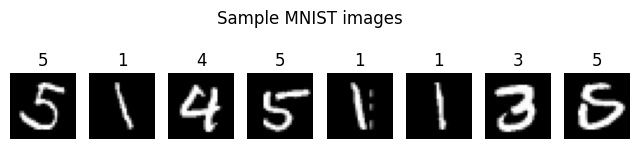

In [10]:
# @title Load MNIST dataset and create DataLoaders; Visualize a few MNIST images

# Transform: convert to tensor and standardize using dataset mean and std
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_full = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

# Split into train/validation
train_size = int(0.9 * len(train_full))
val_size = len(train_full) - train_size
train_dataset, val_dataset = random_split(train_full, [train_size, val_size])

print(f"Train size: {len(train_dataset)}, Val size: {len(val_dataset)}, Test size: {len(test_dataset)}")

batch_size = 64   # you may change this if you like

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=batch_size, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=batch_size, shuffle=False)

print(f"Train batches: {len(train_loader)}, Val batches: {len(val_loader)}, Test batches: {len(test_loader)}")

#Visualize a few MNIST images
examples = enumerate(train_loader)
batch_idx, (example_data, example_targets) = next(examples)

plt.figure(figsize=(8, 2))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(example_data[i][0].cpu().numpy(), cmap="gray")
    plt.title(str(example_targets[i].item()))
    plt.axis("off")
plt.suptitle("Sample MNIST images")
plt.show()


In [ ]:
# @title Define a Fully Connected Neural Network (FNN)

class FNN(nn.Module):
    def __init__(self):
        super().__init__()
        # TODO: define the layers of the FNN.
        # Suggested architecture (but you may choose your own):
        #   - Linear(784, x1)
        #   - Linear(x1, x2) # you can have more hidden laryer
        #   - Linear(x2, x.)...
        #   - Linear(x., 10)
        #
        # Hint: store layers as:
        #   self.fc1 = ...
        #   self.fc2 = ...
        #   self.fc3 = ...

        raise NotImplementedError("TODO: define FNN layers in __init__")

    def forward(self, x):
        """
        x: tensor of shape (batch_size, 1, 28, 28)
        Returns: logits of shape (batch_size, 10)
        """
        # TODO:
        #  1. Flatten x to shape (batch_size, 784)
        #  2. Apply your linear layers such as ReLU activations between them

        raise NotImplementedError("TODO: implement forward pass of FNN")

In [ ]:
# @title Training and evaluation functions

def train_one_epoch(model, optimizer, data_loader, loss_fn, device):
    """
    Train the model for one epoch over data_loader.
    Returns average training loss.
    """
    model.train()
    running_loss = 0.0
    total_samples = 0

    for images, labels in data_loader:
        images, labels = images.to(device), labels.to(device)

        # TODO:
        #  1. Zero the gradients.
        #  2. Forward pass through model.
        #  3. Compute loss.
        #  4. Backward pass.
        #  5. Optimizer step.
        #  6. Accumulate running_loss and total_samples.
        #
        # Hint: labels.size(0) gives the batch size.

        raise NotImplementedError("TODO: implement train_one_epoch")

    avg_loss = running_loss / total_samples
    return avg_loss


def evaluate(model, data_loader, loss_fn, device):
    """
    Evaluate the model on data_loader.

    Returns:
      - avg_loss: average loss over all samples
      - accuracy: sklearn accuracy_score
      - macro_f1: sklearn macro-averaged F1-score
    """
    model.eval()
    running_loss = 0.0
    total_samples = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in data_loader:
            images, labels = images.to(device), labels.to(device)

            # TODO:
            #  1. Forward pass through model to get logits.
            #  2. Compute loss.
            #  3. Accumulate running_loss and total_samples.
            #  4. Get predicted class indices using argmax.
            #  5. Move predictions and labels to CPU and store them
            #     (e.g. all_preds.append(...), all_labels.append(...)).

            raise NotImplementedError("TODO: implement evaluate (forward + collect preds/labels)")

    # TODO: compute average loss
    # avg_loss = ...

    # TODO:
    #  1. Concatenate all predictions and labels across batches.
    #  2. Compute accuracy_score and macro F1 using sklearn.
    #
    #   all_preds = np.concatenate(all_preds)
    #   all_labels = np.concatenate(all_labels)
    #   accuracy = accuracy_score(...)
    #   macro_f1 = f1_score(..., average="macro")

    raise NotImplementedError("TODO: compute avg_loss, accuracy, and macro_f1 and return them")

In [ ]:
# @title Train the Fully Connected Neural Network (with timing + early stopping)

import time

# TODO: create model, loss function, and optimizer
#   model =
#   loss_fn =
#   optimizer =
raise NotImplementedError("TODO: create FNN model, loss function, and optimizer")

num_epochs = 500   # large max, we will rely on early stopping; you can change
patience   = 10    # how many epochs without improvement before stopping, you can change

train_losses = []
val_losses   = []
val_accuracies = []
val_f1s       = []

best_val_loss = np.inf   # or float("inf")
patience_counter = 0

for epoch in range(1, num_epochs + 1):
    epoch_start_time = time.time()

    # --- Training ---
    # TODO: call train_one_epoch and store the result in train_loss
    #   train_loss = ...
    raise NotImplementedError("TODO: call train_one_epoch for FNN")

    # --- Validation ---
    # TODO: call evaluate and store the returned values:
    #   val_loss, val_acc, val_f1 = ...
    raise NotImplementedError("TODO: call evaluate for FNN")

    epoch_time = time.time() - epoch_start_time

    # TODO: store metrics for this epoch in the lists above:
    #   - train_losses
    #   - val_losses
    #   - val_accuracies
    #   - val_f1s
    raise NotImplementedError("TODO: append metrics to history lists")

    # TODO: print a summary line for this epoch including:
    #   epoch index, train_loss, val_loss, val_acc, val_f1, epoch_time
    # Hint: use an f-string like:
    #   f"Epoch {epoch:03d} | Train: ... | Val: ... | Time: ... s"
    raise NotImplementedError("TODO: print training progress for this epoch")

    # --- Early stopping based on val_loss ---
    # TODO:
    #  1. If val_loss is lower than best_val_loss:
    #       - update best_val_loss
    #       - reset patience_counter to 0
    #  2. Otherwise:
    #       - increase patience_counter by 1
    #  3. If patience_counter >= patience:
    #       - print a message about early stopping
    #       - break the loop
    raise NotImplementedError("TODO: implement early stopping logic for FNN")


In [ ]:
# @title Plot FNN training and validation curves

# TODO:
#  1. Create a list/array of epoch indices (e.g. range(len(train_losses))).
#  2. Plot training loss and validation loss vs epoch.
#  3. Optionally, plot validation accuracy or F1 in a second figure.

raise NotImplementedError("TODO: implement plotting of FNN loss/metrics")

In [ ]:
# @title Evaluate FNN on the test set

# TODO:
#  1. Use the evaluate(...) function on test_loader.
#  2. Print test loss, test accuracy, and test macro F1.

raise NotImplementedError("TODO: evaluate trained FNN on test set")

In [ ]:
# @title Define a simple Convolutional Neural Network (CNN)

class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        """
        Input:  (batch_size, 1, 28, 28) # MNIST
        """
        # TODO: define the CNN architecture.
        # Block 1:
        #   - conv1: Conv2d()
        #    - activation: ReLU
        #    - pooling:   MaxPool2d()
        # Block 2, Block 3, etc. (depends how many Convolutional layers you want)
        # Fully connected NN
        #   - fc1: Linear()
        #   - ...

        raise NotImplementedError("TODO: define CNN layers in __init__")

    def forward(self, x):
        """
        x: tensor of shape (batch_size, 1, 28, 28)
        Returns: logits of shape (batch_size, 10)
        """
        # TODO:
        #  1. Apply first conv layer + ReLU + pooling.
        #  2. Apply second conv layer + ReLU + pooling.
        #      Apply third, etc if you have more in the __init__(self) part
        #  3. Flatten the output.
        #  4. Apply fully connected layers with ReLU in between.
        #  5. Return logits (no softmax).

        raise NotImplementedError("TODO: implement forward pass of CNN")

In [ ]:
# @title Train the CNN on MNIST

import time

# TODO: create CNN model, loss function, and optimizer
#   cnn_model =
#   loss_fn_cnn =
#   optimizer_cnn =
raise NotImplementedError("TODO: create CNN model, loss function, and optimizer")

num_epochs_cnn = 500   # large upper bound, you can change
patience_cnn   = 10    # early stopping patience, you can change

train_losses_cnn = []
val_losses_cnn   = []
val_accuracies_cnn = []
val_f1s_cnn       = []

best_val_loss_cnn = np.inf
patience_counter_cnn = 0

for epoch in range(1, num_epochs_cnn + 1):
    epoch_start_time = time.time()

    # --- Training ---
    # TODO: train the CNN for one epoch
    #   train_loss_cnn = train_one_epoch(...)
    raise NotImplementedError("TODO: call train_one_epoch for CNN")

    # --- Validation ---
    # TODO: evaluate the CNN on the validation set
    #   val_loss_cnn, val_acc_cnn, val_f1_cnn = evaluate(...)
    raise NotImplementedError("TODO: call evaluate for CNN")

    epoch_time = time.time() - epoch_start_time

    # TODO: store metrics in the corresponding lists
    raise NotImplementedError("TODO: append CNN metrics to history lists")

    # TODO: print a summary line including epoch, losses, accuracy, F1, and epoch_time
    raise NotImplementedError("TODO: print CNN training progress for this epoch")

    # --- Early stopping for CNN ---
    # TODO:
    #  1. Compare val_loss_cnn with best_val_loss_cnn.
    #  2. Update best_val_loss_cnn and reset patience_counter_cnn if improved.
    #  3. Otherwise, increase patience_counter_cnn.
    #  4. If patience_counter_cnn >= patience_cnn, print message and break.
    raise NotImplementedError("TODO: implement early stopping logic for CNN")

In [ ]:
# @title Plot CNN training and validation curves

# TODO:
#  1. Plot train_losses_cnn and val_losses_cnn vs epoch.

raise NotImplementedError("TODO: implement plotting of CNN loss/metrics")

In [ ]:
# @title Evaluate CNN on the test set

# TODO:
#  1. Use the evaluate(...) function with the trained CNN model and test_loader.
#  2. Print test loss, test accuracy, and test macro F1 for the CNN.

raise NotImplementedError("TODO: evaluate trained CNN on test set")

#Visualizing CNN Filters and Feature Maps (MNIST)

1. Visualize the **learned filters** of the first convolutional layer.
2. Visualize the **feature maps** (activations) produced by the CNN for a sample input image.

You can use the trained CNN model from the previous exercise.
Fill in all `TODO` sections and remove the corresponding `NotImplementedError`.

Label: 7


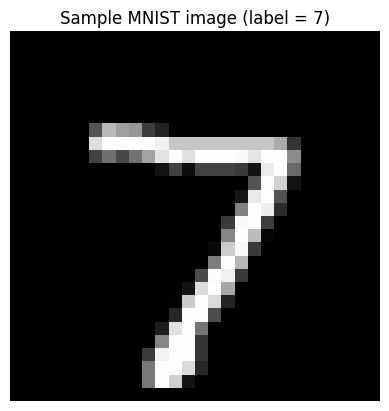

In [19]:
# @title Select one MNIST test image

# We take a single batch from the test loader and pick one image
test_iter = iter(test_loader)
images, labels = next(test_iter)

#choose an index of the image inside the batch (0..batch_size-1)
idx = 0  # for example, take the first image in the batch; you can chose other image
sample_img = images[idx:idx+1]   # shape: (1, 1, 28, 28)
sample_label = labels[idx].item()

print("Label:", sample_label)

plt.imshow(sample_img[0, 0].cpu().numpy(), cmap="gray")
plt.axis("off")
plt.title(f"Sample MNIST image (label = {sample_label})")
plt.show()

In [ ]:
# @title Visualize first-layer convolution filters (conv1)

# We assume your CNN model is called `cnn_model`.
# If you used a different name, change it here.
model = cnn_model

# TODO: get the weight tensor of the first conv layer
# Hint: something like model.conv1.weight
conv1_weights = None
raise NotImplementedError("TODO: get conv1 weights from the model")

print("conv1_weights shape:", conv1_weights.shape)  # (out_channels, in_channels, kH, kW)

# Move to CPU and convert to numpy
w = conv1_weights.detach().cpu().numpy()

num_filters = w.shape[0]
in_channels = w.shape[1]

# For MNIST, in_channels should be 1.
assert in_channels == 1, "Expected 1 input channel for MNIST."

# Plot all filters as small 2D images
cols = 8
rows = int(np.ceil(num_filters / cols))

plt.figure(figsize=(2 * cols, 2 * rows))
for i in range(num_filters):
    plt.subplot(rows, cols, i + 1)
    # Each filter: w[i, 0, :, :]
    filt = w[i, 0, :, :]
    plt.imshow(filt, cmap="gray")
    plt.axis("off")
    plt.title(f"F{i}")
plt.suptitle("First-layer conv filters (conv1)")
plt.tight_layout()
plt.show()

In [ ]:
# @title Compute feature maps (activations) for conv1 and conv2

import torch.nn.functional as F

model.eval()

# TODO:
#  1. Move sample_img to device.
#  2. Compute activations after:
#       - conv1 (before pooling)
#       - conv2 (before pooling)
#     You can manually call model.conv1, model.conv2, model.pool, etc.
#
# For simplicity, use manual calls like:
#   x = sample_img.to(device)
#   a1 = F.relu(model.conv1(x))      # activations after conv1
#   p1 = model.pool(a1)              # if you have a shared pool
#   a2 = F.relu(model.conv2(p1))     # activations after conv2
#
#  move a1 and a2 back to CPU.

a1 = None  # activations after conv1 (shape: 1, C1, H1, W1)
a2 = None  # activations after conv2 (shape: 1, C2, H2, W2)

raise NotImplementedError("TODO: compute a1, a2 using model.conv1/conv2 and ReLU")

print("a1 shape:", a1.shape)
print("a2 shape:", a2.shape)

a1 = a1.detach().cpu().numpy()
a2 = a2.detach().cpu().numpy()

In [ ]:
# @title Visualize feature maps for conv1 or conv2

def plot_feature_maps(feature_maps, title, max_channels=16):
    """
    feature_maps: numpy array of shape (1, C, H, W)
    """
    C = feature_maps.shape[1]
    num = min(C, max_channels)

    cols = 8
    rows = int(np.ceil(num / cols))

    plt.figure(figsize=(2 * cols, 2 * rows))
    for i in range(num):
        plt.subplot(rows, cols, i + 1)
        fm = feature_maps[0, i, :, :]
        plt.imshow(fm, cmap="gray")
        plt.axis("off")
        plt.title(f"C{i}")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

# TODO: call the helper function for a1 and a2
# Example:
#   plot_feature_maps(a1, "Feature maps after conv1")
#   plot_feature_maps(a2, "Feature maps after conv2")

raise NotImplementedError("TODO: visualize conv1 and conv2 feature maps using plot_feature_maps")